# EK80 Gas Flux Calculation

### 1. Environment Setup & Imports

In [1]:
# Import different environment packages

import geopandas as gpd
import echopype as ep
import xarray as xr
import matplotlib.pyplot as plt

# Print versions to confirm the correct environment is active
print(f"Echopype: {ep.__version__}")
print(f"GeoPandas: {gpd.__version__}")
print(f"Xarray: {xr.__version__}")

# Read a public, lightweight GeoJSON map of the world from a reliable URL
url = "http://d2ad6b4ur7yvpq.cloudfront.net/naturalearth-3.3.0/ne_110m_land.geojson"
world = gpd.read_file(url)

# Plot it to confirm matplotlib & spatial engines are talking nicely
#fig, ax = plt.subplots(figsize=(10, 5))
#world.plot(ax=ax, color='lightgrey', edgecolor='white')
#plt.title("Spatial Stack Active & Verified!")
#plt.show()

Echopype: 0.11.1
GeoPandas: 1.1.4
Xarray: 2026.7.0


### 1.2 Define file paths and Data convertion from RAW to NetCDF format

In [2]:
import os
import tempfile
from pathlib import Path
import echopype as ep # Echopype: Convert and calibrate to TS/Sv

# 1. Define paths
raw_file_path = Path(r"C:\Users\nilr\OneDrive - Universitetssenteret på Svalbard AS\PhD\2026\AFG_CryoSeep\Bubble size distribution\data\EK06\Cryo-seep-EK80-06-D20260319-T103939.raw")
onedrive_nc_path = raw_file_path.with_suffix(".nc")

# 2. Set up a LOCAL temporary directory to process the file without OneDrive interference
local_temp_dir = Path("C:/Temp_Acoustics")
local_temp_dir.mkdir(parents=True, exist_ok=True)
local_nc_path = local_temp_dir / raw_file_path.with_suffix(".nc").name

print(f"Raw Input:      {raw_file_path}")
print(f"Local Sandbox:  {local_nc_path}")
print(f"OneDrive Dest:  {onedrive_nc_path}\n")

# 3. Clean up any stale file handles that might be locking the file in your system
import gc
gc.collect() 

# 4. Convert to local directory first
if not onedrive_nc_path.exists():
    print("Converting binary data locally (avoiding OneDrive sync locks)...")
    
    # Initialize parser
    ed = ep.open_raw(raw_file=str(raw_file_path), sonar_model="EK80")
    
    # Save directly to our fast local disk
    ed.to_netcdf(save_path=str(local_nc_path), overwrite=True)
    print("Conversion complete locally!")
    
    # Move the finalized, fully closed file to OneDrive
    print("Moving finalized NetCDF to OneDrive...")
    try:
        if local_nc_path.exists():
            import shutil
            shutil.move(str(local_nc_path), str(onedrive_nc_path))
            print("Successfully moved file to OneDrive!")
    except Exception as e:
        print(f"Failed to move file to OneDrive automatically: {e}")
        print(f"Your file is safely stored locally at: {local_nc_path}")
        # Update path to use local fallback so you don't get blocked
        onedrive_nc_path = local_nc_path
else:
    print(f"Converted file already exists on OneDrive. Skipping conversion step.")

Raw Input:      C:\Users\nilr\OneDrive - Universitetssenteret på Svalbard AS\PhD\2026\AFG_CryoSeep\Bubble size distribution\data\EK06\Cryo-seep-EK80-06-D20260319-T103939.raw
Local Sandbox:  C:\Temp_Acoustics\Cryo-seep-EK80-06-D20260319-T103939.nc
OneDrive Dest:  C:\Users\nilr\OneDrive - Universitetssenteret på Svalbard AS\PhD\2026\AFG_CryoSeep\Bubble size distribution\data\EK06\Cryo-seep-EK80-06-D20260319-T103939.nc

Converted file already exists on OneDrive. Skipping conversion step.


### 2. Import CTD profile for environmental parameters

#### Calculate mean sound speed $c$ and absorption $\alpha$ from your CTD profile over the water column

In [3]:
# Import CTD profile

import pandas as pd
import numpy as np

# Path to your thinned CTD CSV
ctd_path = r"C:\Users\nilr\OneDrive - Universitetssenteret på Svalbard AS\PhD\2026\AFG_CryoSeep\Bubble size distribution\data\CTD\VL_81575_260319120127_thinned.csv"

# Load CTD: row 0 is column names, line 1 (row 1) contains units so we skip it
ctd_df = pd.read_csv(ctd_path, header=0, skiprows=[1])

# Convert columns to numeric explicitly
ctd_df["Temperature"] = pd.to_numeric(ctd_df["Temperature"], errors="coerce")
ctd_df["Salinity"] = pd.to_numeric(ctd_df["Salinity"], errors="coerce")

# Calculate means across the cast
mean_temp = ctd_df["Temperature"].mean()
mean_sal  = ctd_df["Salinity"].mean()
mean_depth = 20.0  # Site depth: 20m

print(f"--- Site Environmental Profile (0-{mean_depth}m) ---")
print(f"Mean Temperature: {mean_temp:.3f} °C")
print(f"Mean Salinity:    {mean_sal:.3f} PSU")
print(f"Site Depth:       {mean_depth} m")

# Pack into echopype env_params dictionary
env_params = {
    "temperature": mean_temp,
    "salinity": mean_sal,
    "pressure": mean_depth  # ~20 dbar for 20m
}

--- Site Environmental Profile (0-20.0m) ---
Mean Temperature: -1.905 °C
Mean Salinity:    16.978 PSU
Site Depth:       20.0 m


### 3. Calibration of Sv and TS with the XML (calibration file)

#### $S_v$ (Volume Backscattering Strength): Measures total backscatter per unit volume. This gives you a clear visual map of the gas plume structure, seafloor, and water column.
#### $TS$ (Target Strength): Measures backscatter from individual point targets. This is what you will use down the line to size individual gas bubbles.

In [4]:
# Parse XML Calibration & Compute Calibrated Sv/TS

import gc
import shutil
from pathlib import Path
import echopype as ep

# 1. Define paths
raw_file_path = Path(r"C:\Users\nilr\OneDrive - Universitetssenteret på Svalbard AS\PhD\2026\AFG_CryoSeep\Bubble size distribution\data\EK06\Cryo-seep-EK80-06-D20260319-T104132.raw")
cal_xml_path = Path(r"C:\Users\nilr\OneDrive - Universitetssenteret på Svalbard AS\PhD\2026\AFG_CryoSeep\Bubble size distribution\data\Calibration\CalibrationDataFile-D20260318-T143745.xml")

onedrive_nc_path = raw_file_path.with_suffix(".nc")

# 2. Local sandbox path
temp_dir = Path("C:/Temp_Acoustics")
temp_dir.mkdir(parents=True, exist_ok=True)
local_nc_path = temp_dir / onedrive_nc_path.name

print(f"Raw Input:       {raw_file_path}")
print(f"Cal XML Input:   {cal_xml_path}")
print(f"Local Sandbox:   {local_nc_path}")
print(f"OneDrive Dest:   {onedrive_nc_path}\n")

# --- CLEANUP EXISTING FILE HANDLES ---
# Close any existing dataset variables if they are still in memory to unlock files
if 'ed_nc' in locals():
    del ed_nc
if 'ds_sv' in locals():
    del ds_sv
if 'ds_ts' in locals():
    del ds_ts
gc.collect()

# Set force_reconvert=True to guarantee conversion using your XML file
force_reconvert = True 

# 3. Convert RAW -> NetCDF with XML Calibration
if force_reconvert or not onedrive_nc_path.exists():
    print("Converting binary raw data WITH external XML calibration locally...")
    
    # Parse raw data with the XML file specified
    ed = ep.open_raw(
        raw_file=str(raw_file_path), 
        sonar_model="EK80", 
        xml_path=str(cal_xml_path)
    )
    
    # Export to local temp directory
    ed.to_netcdf(save_path=str(local_nc_path), overwrite=True)
    print("Local conversion complete!")
    
    # Try copying/moving to OneDrive
    try:
        shutil.copy2(str(local_nc_path), str(onedrive_nc_path))
        print("Successfully updated OneDrive NetCDF with XML calibration!")
    except Exception as e:
        print(f"OneDrive copy warning (file locked by OneDrive sync or Python): {e}")
        print("Proceeding using local sandbox file directly...")
        onedrive_nc_path = local_nc_path
else:
    print("Staging existing OneDrive NetCDF file locally...")
    try:
        shutil.copy2(str(onedrive_nc_path), str(local_nc_path))
    except Exception as e:
        print(f"Local copy warning ({e}). Reading directly from local path...")

# 4. Open the NetCDF dataset from local fast disk
print("\nLoading converted NetCDF dataset...")
ed_nc = ep.open_converted(str(local_nc_path))

# 5. Compute Calibrated Sv (Volume Backscattering)
print("Computing Calibrated Sv (FM Wideband)...")
ds_sv = ep.calibrate.compute_Sv(
    ed_nc, 
    waveform_mode="FM", 
    encode_mode="complex",
    env_params=env_params
)

# 6. Compute Calibrated TS (Target Strength)
print("Computing Calibrated TS (FM Wideband)...")
ds_ts = ep.calibrate.compute_TS(
    ed_nc, 
    waveform_mode="FM", 
    encode_mode="complex",
    env_params=env_params
)

print("\nCalibration complete! Sv and TS datasets created using XML sphere calibration.")

Raw Input:       C:\Users\nilr\OneDrive - Universitetssenteret på Svalbard AS\PhD\2026\AFG_CryoSeep\Bubble size distribution\data\EK06\Cryo-seep-EK80-06-D20260319-T104132.raw
Cal XML Input:   C:\Users\nilr\OneDrive - Universitetssenteret på Svalbard AS\PhD\2026\AFG_CryoSeep\Bubble size distribution\data\Calibration\CalibrationDataFile-D20260318-T143745.xml
Local Sandbox:   C:\Temp_Acoustics\Cryo-seep-EK80-06-D20260319-T104132.nc
OneDrive Dest:   C:\Users\nilr\OneDrive - Universitetssenteret på Svalbard AS\PhD\2026\AFG_CryoSeep\Bubble size distribution\data\EK06\Cryo-seep-EK80-06-D20260319-T104132.nc

Converting binary raw data WITH external XML calibration locally...
Local conversion complete!
Successfully updated OneDrive NetCDF with XML calibration!

Loading converted NetCDF dataset...
Computing Calibrated Sv (FM Wideband)...
Computing Calibrated TS (FM Wideband)...

Calibration complete! Sv and TS datasets created using XML sphere calibration.


### 4.1 Render Full 20m Water Column Echogram

             BACKGROUND NOISE THRESHOLD DIAGNOSTICS         
 Water Column Depth Evaluated : 3.0 m to 17.5 m
 Ambient Sv Median (p50)      : -67.92 dB
 Ambient Sv 95th Percentile   : -46.90 dB
 Configured Threshold         : -68.0 dB
 Status                       : Warning - Threshold may be below median background noise!



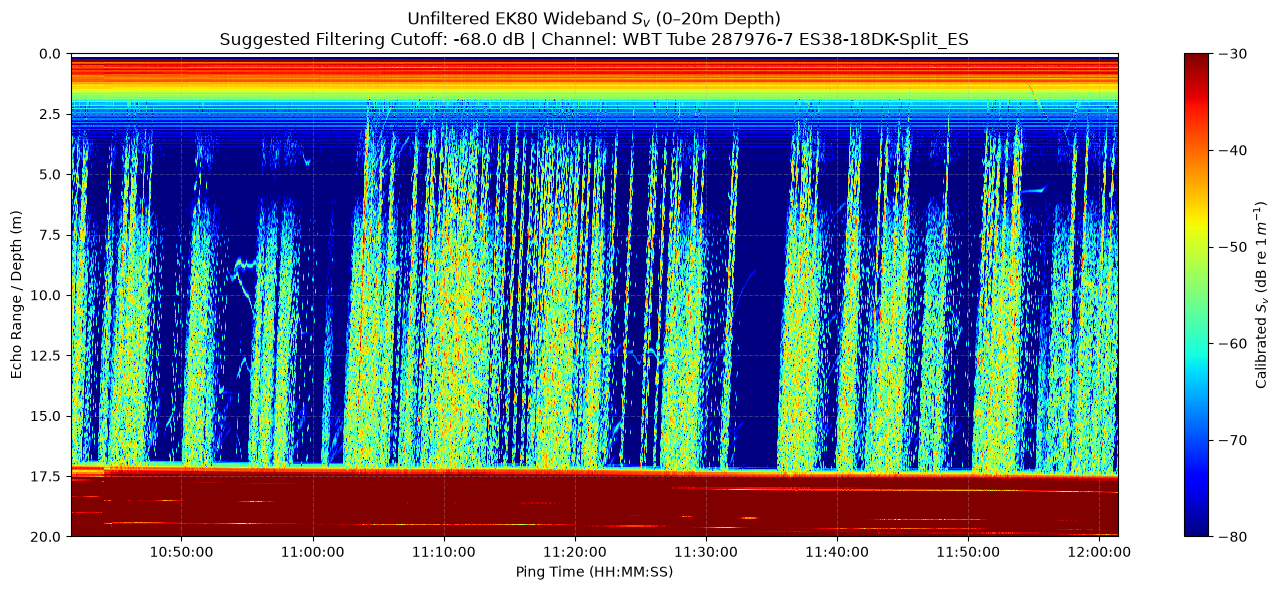

In [5]:
# Render Full 20m Water Column & Estimate Background Noise Threshold

import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import numpy as np

# 1. Extract channel
channel_name = ds_sv.channel.values[0]
sv_da = ds_sv.sel(channel=channel_name)['Sv'].squeeze()

# 2. Extract clean 1D depth vector without NaNs
if 'echo_range' in ds_sv:
    echo_range_raw = ds_sv.sel(channel=channel_name)['echo_range'].squeeze().values
    if echo_range_raw.ndim > 1:
        echo_range = echo_range_raw[0, :]
    else:
        echo_range = echo_range_raw
else:
    echo_range = sv_da.range_sample.values

valid_range_mask = ~np.isnan(echo_range)
echo_range = echo_range[valid_range_mask]

# 3. Align Sv data array to valid range indices and mask down to 20m
sv_valid = sv_da.isel(range_sample=valid_range_mask)
sv_masked = sv_valid.where(echo_range <= 20.0)

# =================================----------------=================
# NOISE THRESHOLD DIAGNOSTICS
# =================================----------------=================
# Isolate mid-water column (3.0m - 17.5m) to avoid surface/bottom ringing
water_column_mask = (echo_range >= 3.0) & (echo_range <= 17.5)
sv_wc_values = sv_valid.where(water_column_mask).values.flatten()
sv_wc_clean = sv_wc_values[~np.isnan(sv_wc_values)]

# Calculate statistics
p5 = np.percentile(sv_wc_clean, 5)
p50 = np.percentile(sv_wc_clean, 50)
p95 = np.percentile(sv_wc_clean, 95)
suggested_threshold = -68.0

print("=" * 60)
print("             BACKGROUND NOISE THRESHOLD DIAGNOSTICS         ")
print("=" * 60)
print(f" Water Column Depth Evaluated : 3.0 m to 17.5 m")
print(f" Ambient Sv Median (p50)      : {p50:.2f} dB")
print(f" Ambient Sv 95th Percentile   : {p95:.2f} dB")
print(f" Configured Threshold         : {suggested_threshold:.1f} dB")
if suggested_threshold > p50:
    print(f" Status                       : Threshold is {suggested_threshold - p50:.1f} dB above median background.")
else:
    print(" Status                       : Warning - Threshold may be below median background noise!")
print("=" * 60 + "\n")

# 4. Prepare Colormap with NaN as white
current_cmap = plt.colormaps['jet'].copy()
current_cmap.set_bad(color="white")

# 5. Plot Unfiltered Echogram
plt.figure(figsize=(14, 6))

mesh = plt.pcolormesh(
    sv_masked.ping_time.values, 
    echo_range, 
    sv_masked.values.T, 
    cmap=current_cmap, 
    vmin=-80, 
    vmax=-30, 
    shading="nearest"
)

plt.gca().invert_yaxis()
plt.ylim(20.0, 0.0)

# Format X-axis time to HH:MM:SS
plt.gca().xaxis.set_major_formatter(DateFormatter('%H:%M:%S'))

cbar = plt.colorbar(mesh)
cbar.set_label("Calibrated $S_v$ (dB re $1\\,m^{-1}$)")

plt.title(f"Unfiltered EK80 Wideband $S_v$ (0–20m Depth)\nSuggested Filtering Cutoff: {suggested_threshold} dB | Channel: {channel_name}", fontsize=12)
plt.xlabel("Ping Time (HH:MM:SS)")
plt.ylabel("Echo Range / Depth (m)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

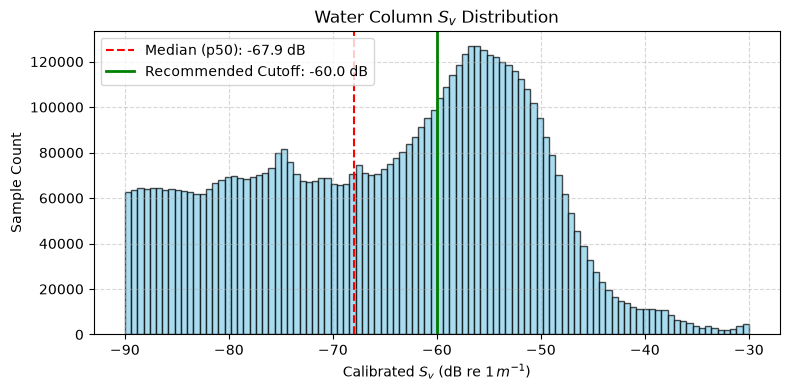

In [6]:
# Quick Histogram to visually confirm the cutoff between noise and bubbles
import matplotlib.pyplot as plt
import numpy as np

# Extract water column Sv values (3m to 17.5m)
water_column_mask = (echo_range >= 3.0) & (echo_range <= 17.5)
sv_vals = sv_valid.where(water_column_mask).values.flatten()
sv_vals = sv_vals[~np.isnan(sv_vals)]

plt.figure(figsize=(8, 4))
plt.hist(sv_vals, bins=100, range=(-90, -30), color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(x=-67.92, color='red', linestyle='--', label='Median (p50): -67.9 dB')
plt.axvline(x=-60.0, color='green', linestyle='-', linewidth=2, label='Recommended Cutoff: -60.0 dB')

plt.xlabel("Calibrated $S_v$ (dB re $1\\,m^{-1}$)")
plt.ylabel("Sample Count")
plt.title("Water Column $S_v$ Distribution")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

##### For acoustic quantification, the threshold should sit above the ambient background noise floor while remaining low enough to capture the edges of the gas plume.
##### Safety margin (SNR): In hydroacoustics, a +6 dB to +10 dB margin above the background median is the standard rule of thumb to ensure clean noise rejection.

### 4.2 Data Filtering & Time Slicing

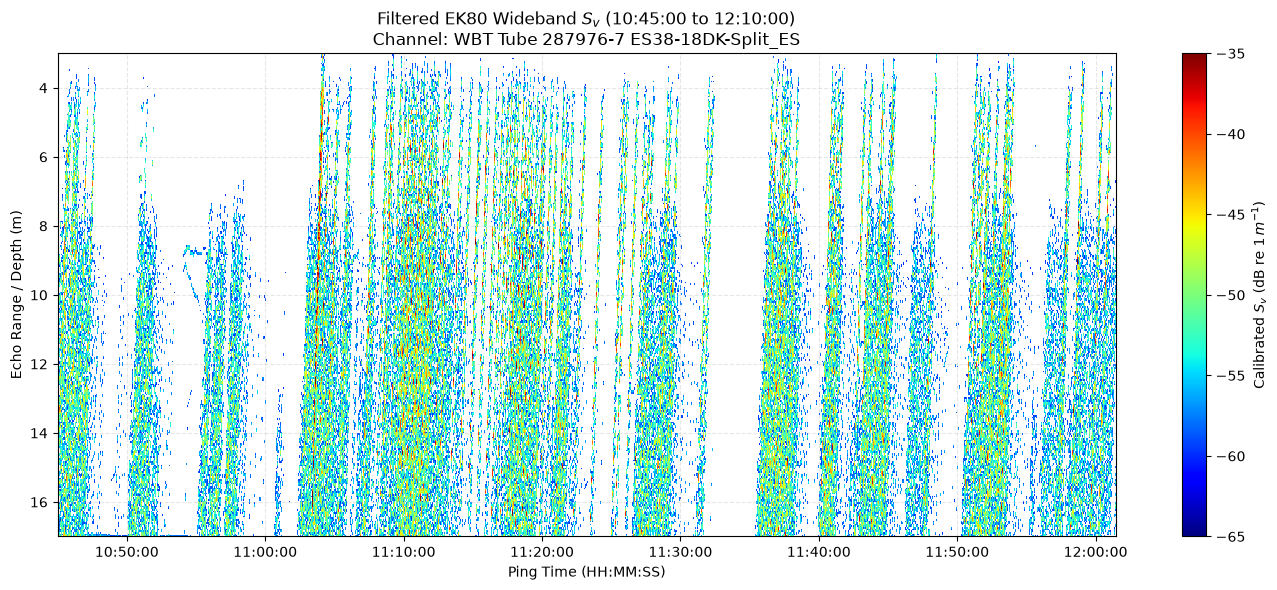

In [7]:
# Master Filtering, Time Slicing & Echogram Plotting Cell

import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import numpy as np
import pandas as pd

# =================================----------------=================
# 1. USER CONFIGURATION PARAMETERS
# =================================----------------=================
# Depth range (meters)
MIN_DEPTH = 3.0
MAX_DEPTH = 17.0

# Noise threshold (dB)
SV_THRESHOLD = -60.0

# Plotting range limits for colorbar (dB)
VMIN = -65
VMAX = -35

# Time slicing settings: set USE_TIME_SLICE = False to plot full recording
USE_TIME_SLICE = True
START_STR = "10:45:00"
END_STR   = "12:10:00"

# Display axis limits (set to 20.0, 0.0 to see full water column, or MAX_DEPTH, MIN_DEPTH to crop)
Y_LIMIT_BOTTOM = 17.0
Y_LIMIT_TOP    = 3.0

# =================================----------------=================
# 2. CHANNEL & 1D DEPTH VECTOR EXTRACTION
# =================================----------------=================
channel_name = ds_sv.channel.values[0]
sv_da = ds_sv.sel(channel=channel_name)['Sv'].squeeze()

if 'echo_range' in ds_sv:
    echo_range_raw = ds_sv.sel(channel=channel_name)['echo_range'].squeeze().values
    if echo_range_raw.ndim > 1:
        echo_range = echo_range_raw[0, :]
    else:
        echo_range = echo_range_raw
else:
    echo_range = sv_da.range_sample.values

# Remove NaNs from coordinate vector and align Sv data
valid_range_mask = ~np.isnan(echo_range)
echo_range = echo_range[valid_range_mask]
sv_valid = sv_da.isel(range_sample=valid_range_mask)

# =================================----------------=================
# 3. TIME SLICING
# =================================----------------=================
if USE_TIME_SLICE:
    base_date = pd.to_datetime(sv_valid.ping_time.values[0]).strftime("%Y-%m-%d")
    t_start = np.datetime64(f"{base_date}T{START_STR}")
    t_end   = np.datetime64(f"{base_date}T{END_STR}")
    sv_target = sv_valid.sel(ping_time=slice(t_start, t_end))
    time_title_str = f"({START_STR} to {END_STR})"
else:
    sv_target = sv_valid
    time_title_str = "(Full Time Range)"

# =================================----------------=================
# 4. FILTERING & MASKING
# =================================----------------=================
# A. Depth Masking
depth_mask = (echo_range >= MIN_DEPTH) & (echo_range <= MAX_DEPTH)
sv_clean = sv_target.where(depth_mask)

# B. Thresholding (remove background noise floor)
sv_clean = sv_clean.where(sv_clean >= SV_THRESHOLD)

# =================================----------------=================
# 5. ECHOGRAM PLOTTING
# =================================----------------=================
current_cmap = plt.colormaps['jet'].copy()
current_cmap.set_bad(color="white")

plt.figure(figsize=(14, 6))

mesh = plt.pcolormesh(
    sv_clean.ping_time.values, 
    echo_range, 
    sv_clean.values.T, 
    cmap=current_cmap, 
    vmin=VMIN, 
    vmax=VMAX, 
    shading="nearest"
)

# Invert Y-axis so surface is at top and seafloor is at bottom
plt.gca().invert_yaxis()
plt.ylim(Y_LIMIT_BOTTOM, Y_LIMIT_TOP)

# Format X-axis timestamps to HH:MM:SS
plt.gca().xaxis.set_major_formatter(DateFormatter('%H:%M:%S'))

cbar = plt.colorbar(mesh)
cbar.set_label("Calibrated $S_v$ (dB re $1\\,m^{-1}$)")

plt.title(f"Filtered EK80 Wideband $S_v$ {time_title_str}\nChannel: {channel_name}", fontsize=12)
plt.xlabel("Ping Time (HH:MM:SS)")
plt.ylabel("Echo Range / Depth (m)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

### 5. Volumetric Backscattering Integration (Gas volume flow rate calculation)

             ACOUSTIC BUBBLE GAS FLUX INTEGRATION RESULTS     
 Depth Range Integrated      : 3.0 m to 17.0 m (Thickness: 14.0 m)
 $S_v$ Filtering Threshold     : -62.0 dB
 Transducer Beamwidth        : 18.0°
 Assumed Bubble Radius ($r$)   : 5.04 mm
 Assumed Rise Velocity ($v$)   : 0.24 m/s
-----------------------------------------------------------------
 Mean Gas Flow Rate          : 0.004 L/min (3.6 mL/min)
 Peak Gas Flow Rate          : 0.058 L/min (58.3 mL/min)


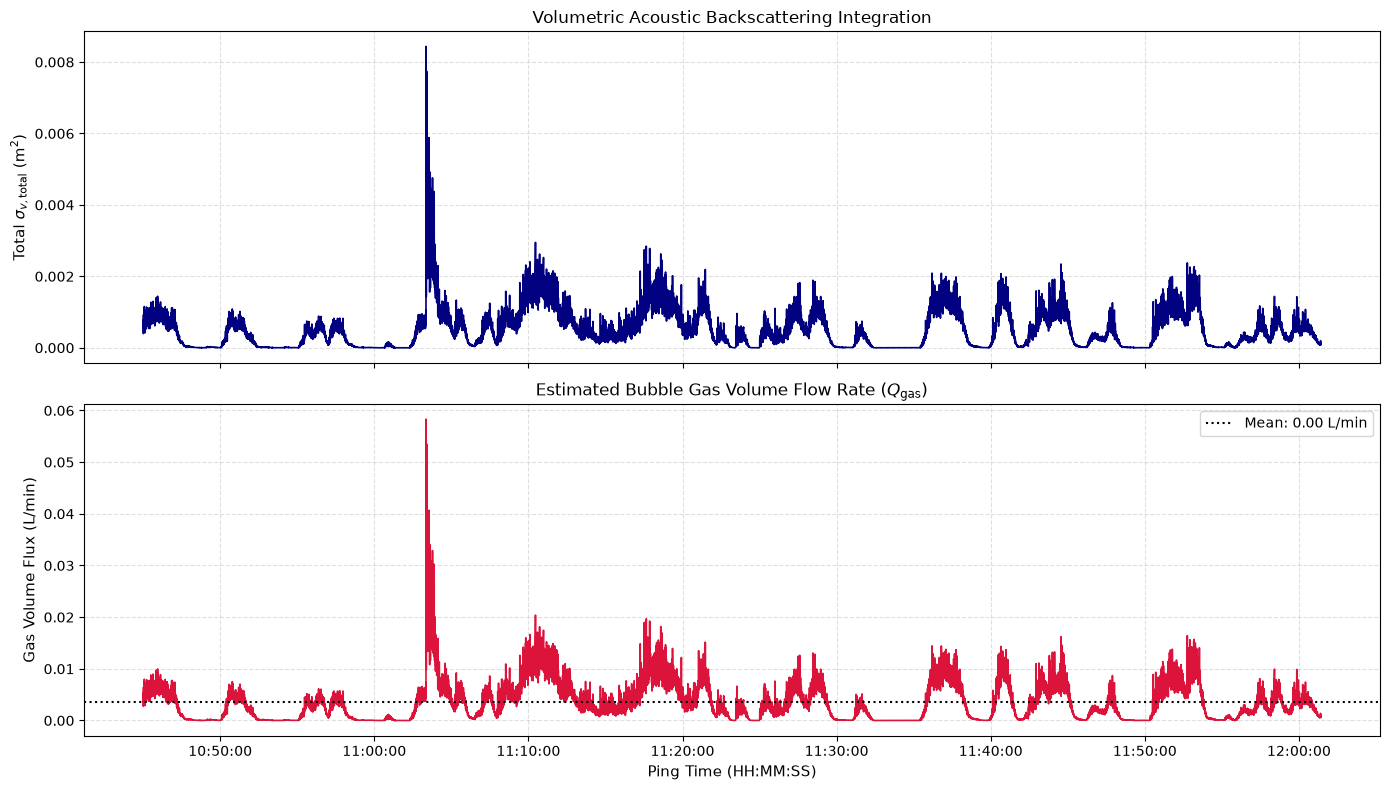

In [8]:
# Step 5: Volumetric Backscattering Integration & Gas Flux Calculation (Updated for 18° Beamwidth)

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter

# ==================================================================
# 1. PHYSICAL & ACOUSTIC PARAMETERS
# ==================================================================
BEAMWIDTH_DEG = 18.0             # Updated EK80 beamwidth (18.0°)

MEAN_BUBBLE_RADIUS_MM = 5.04       # Empirical Mean Volume Radius (mm)
RISE_VELOCITY_MS = 0.24           # Empirical Tracked Rise Velocity (m/s)

SV_CUTOFF_DB = -62.0              # Background noise cutoff (dB)
Z_MIN = 3.0
Z_MAX = 17.0

# ==================================================================
# 2. PREPARE SV DATAARRAY IN LINEAR DOMAIN
# ==================================================================
# Filter values below -60.0 dB
sv_db = sv_clean.copy()
sv_db_filtered = sv_db.where(sv_db >= SV_CUTOFF_DB, other=np.nan)

# Convert to Linear Volume Backscattering Coefficient s_v (1/m)
sv_linear = 10.0 ** (sv_db_filtered / 10.0)
sv_linear = sv_linear.fillna(0.0)  # NaNs set to 0 for integration

# ==================================================================
# 3. ENSONIFIED VOLUME GEOMETRY (BEAM CONE)
# ==================================================================
# Range resolution (dz) in meters
dz = float(np.abs(np.diff(echo_range).mean()))

# Beam half-angle in radians
half_angle_rad = np.radians(BEAMWIDTH_DEG / 2.0)

# Calculate sample cell volume V_cell(z) at each depth z
beam_radius_z = echo_range * np.tan(half_angle_rad)
footprint_area_z = np.pi * (beam_radius_z ** 2)
v_cell_z = footprint_area_z * dz  # 1D numpy array corresponding to echo_range

# Wrap v_cell into an xarray DataArray for automatic dimension matching with sv_linear
range_dim_name = 'range_sample' if 'range_sample' in sv_linear.dims else 'echo_range'
v_cell_da = xr.DataArray(v_cell_z, dims=[range_dim_name], coords={range_dim_name: sv_linear[range_dim_name]})

# ==================================================================
# 4. VOLUMETRIC INTEGRATION PER PING (XARRAY-NATIVE)
# ==================================================================
# Multiply s_v (1/m) by V_cell (m³) safely across the depth dimension
sigma_v_integrated = (sv_linear * v_cell_da).sum(dim=range_dim_name)
sigma_v_total_per_ping = sigma_v_integrated.values

# ==================================================================
# 5. GAS VOLUME & FLUX ESTIMATION
# ==================================================================
# Representative Single-Bubble Volume (m³)
r_m = MEAN_BUBBLE_RADIUS_MM / 1000.0
v_single_bubble = (4.0 / 3.0) * np.pi * (r_m ** 3)

# Single bubble backscattering cross-section (geometric/spherical cross section)
sigma_bs_single = np.pi * (r_m ** 2)

# Total estimated gas volume in the beam plume slice at any given instant (m³)
v_gas_instantaneous = (sigma_v_total_per_ping / sigma_bs_single) * v_single_bubble

# Residence time in plume slice (seconds)
plume_thickness_m = Z_MAX - Z_MIN
tau_residence = plume_thickness_m / RISE_VELOCITY_MS

# Gas Volume Flow Rate Q_gas
q_gas_m3_per_s = v_gas_instantaneous / tau_residence
q_gas_L_per_min = q_gas_m3_per_s * 1000.0 * 60.0
q_gas_mL_per_min = q_gas_L_per_min * 1000.0

# ==================================================================
# 6. TIME SERIES SUMMARY & PLOTTING
# ==================================================================
ping_times = pd.to_datetime(sv_clean.ping_time.values)

print("=" * 65)
print("             ACOUSTIC BUBBLE GAS FLUX INTEGRATION RESULTS     ")
print("=" * 65)
print(f" Depth Range Integrated      : {Z_MIN:.1f} m to {Z_MAX:.1f} m (Thickness: {plume_thickness_m:.1f} m)")
print(f" $S_v$ Filtering Threshold     : {SV_CUTOFF_DB:.1f} dB")
print(f" Transducer Beamwidth        : {BEAMWIDTH_DEG:.1f}°")
print(f" Assumed Bubble Radius ($r$)   : {MEAN_BUBBLE_RADIUS_MM:.2f} mm")
print(f" Assumed Rise Velocity ($v$)   : {RISE_VELOCITY_MS:.2f} m/s")
print("-" * 65)
print(f" Mean Gas Flow Rate          : {np.mean(q_gas_L_per_min):.3f} L/min ({np.mean(q_gas_mL_per_min):.1f} mL/min)")
print(f" Peak Gas Flow Rate          : {np.max(q_gas_L_per_min):.3f} L/min ({np.max(q_gas_mL_per_min):.1f} mL/min)")
print("=" * 65)

# Plotting
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Plot 1: Total Integrated Acoustic Backscattering Cross-Section
ax1.plot(ping_times, sigma_v_total_per_ping, color='navy', linewidth=1.2)
ax1.set_ylabel(r"Total $\sigma_{v,\mathrm{total}}$ ($\mathrm{m}^2$)", fontsize=11)
ax1.set_title("Volumetric Acoustic Backscattering Integration", fontsize=12)
ax1.grid(True, linestyle="--", alpha=0.4)

# Plot 2: Volumetric Gas Flow Rate
ax2.plot(ping_times, q_gas_L_per_min, color='crimson', linewidth=1.2)
ax2.axhline(y=np.mean(q_gas_L_per_min), color='black', linestyle=':', label=rf"Mean: {np.mean(q_gas_L_per_min):.2f} L/min")
ax2.set_ylabel("Gas Volume Flux (L/min)", fontsize=11)
ax2.set_xlabel("Ping Time (HH:MM:SS)", fontsize=11)
ax2.set_title(r"Estimated Bubble Gas Volume Flow Rate ($Q_{\mathrm{gas}}$)", fontsize=12)
ax2.xaxis.set_major_formatter(DateFormatter('%H:%M:%S'))
ax2.legend(loc="upper right")
ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [9]:
# ==============================================================================
# BUBBLE GAS FLUX STATISTICAL ANALYSIS
# ==============================================================================

import numpy as np
import pandas as pd

# 1. COMPUTE KEY DESCRIPTIVE STATISTICS (mL/min & L/min)
flux_stats = {
    "Mean Flux": np.nanmean(q_gas_mL_per_min),
    "Median Flux": np.nanmedian(q_gas_mL_per_min),
    "Peak (Max) Flux": np.nanmax(q_gas_mL_per_min),
    "Min Active Flux": np.nanmin(q_gas_mL_per_min[q_gas_mL_per_min > 0]), # Excludes 0s
    "Std Deviation": np.nanstd(q_gas_mL_per_min),
    "25th Percentile (Q1)": np.nanpercentile(q_gas_mL_per_min, 25),
    "75th Percentile (Q3)": np.nanpercentile(q_gas_mL_per_min, 75),
    "Interquartile Range (IQR)": np.nanpercentile(q_gas_mL_per_min, 75) - np.nanpercentile(q_gas_mL_per_min, 25)
}

# 2. TOTAL INTEGRATED GAS VOLUME RELEASED OVER SAMPLING DURATION
# Convert ping times to seconds to compute time step dt per ping
ping_times_sec = (pd.to_datetime(ping_times) - pd.to_datetime(ping_times[0])).total_seconds().values
dt_sec = np.gradient(ping_times_sec)  # Time delta per ping in seconds

# Total accumulated volume in Liters (integrated rate over time)
total_volume_L = np.sum(q_gas_m3_per_s * dt_sec) * 1000.0  # m³ -> Liters
total_duration_min = (ping_times_sec[-1] - ping_times_sec[0]) / 60.0

# 3. DISPLAY RESULTS SUMMARY
print("=" * 65)
print("             STATION EK06 GAS FLUX STATISTICAL SUMMARY            ")
print("=" * 65)
print(f" Total Observation Duration     : {total_duration_min:.2f} minutes")
print(f" Total Integrated Gas Released  : {total_volume_L:.3f} Liters ({total_volume_L * 1000:.1f} mL)")
print("-" * 65)
print(f" Mean Flow Rate                 : {flux_stats['Mean Flux']:.2f} mL/min  ({flux_stats['Mean Flux']/1000:.4f} L/min)")
print(f" Median Flow Rate               : {flux_stats['Median Flux']:.2f} mL/min  ({flux_stats['Median Flux']/1000:.4f} L/min)")
print(f" Peak (Maximum) Flow Rate       : {flux_stats['Peak (Max) Flux']:.2f} mL/min  ({flux_stats['Peak (Max) Flux']/1000:.4f} L/min)")
print(f" Minimum Active Flow Rate       : {flux_stats['Min Active Flux']:.2f} mL/min  ({flux_stats['Min Active Flux']/1000:.4f} L/min)")
print("-" * 65)
print(f" Standard Deviation             : {flux_stats['Std Deviation']:.2f} mL/min")
print(f" Interquartile Range (Q1 - Q3)  : {flux_stats['25th Percentile (Q1)']:.2f} to {flux_stats['75th Percentile (Q3)']:.2f} mL/min")
print("=" * 65)

             STATION EK06 GAS FLUX STATISTICAL SUMMARY            
 Total Observation Duration     : 76.44 minutes
 Total Integrated Gas Released  : 0.272 Liters (272.0 mL)
-----------------------------------------------------------------
 Mean Flow Rate                 : 3.59 mL/min  (0.0036 L/min)
 Median Flow Rate               : 2.66 mL/min  (0.0027 L/min)
 Peak (Maximum) Flow Rate       : 58.33 mL/min  (0.0583 L/min)
 Minimum Active Flow Rate       : 0.00 mL/min  (0.0000 L/min)
-----------------------------------------------------------------
 Standard Deviation             : 3.73 mL/min
 Interquartile Range (Q1 - Q3)  : 0.31 to 5.65 mL/min


#### Flux calculation ignoring the quiescent (zero-flux) periods

In [10]:
# ==============================================================================
# ACTIVE-ONLY BUBBLE GAS FLUX ANALYSIS (IGNORING QUIESCENT PERIODS)
# ==============================================================================

import numpy as np
import pandas as pd

# 1. DEFINE ACTIVE SEEP THRESHOLD (mL/min)
# Ignores periods where flux drops to zero or background acoustic noise
ACTIVE_THRESHOLD_ML_MIN = 0.1  # Adjust if your background noise floor differs

# Mask array for active periods
active_mask = q_gas_mL_per_min > ACTIVE_THRESHOLD_ML_MIN
q_active_ml_min = q_gas_mL_per_min[active_mask]
q_active_m3_s = q_gas_m3_per_s[active_mask]

# 2. TIME DURATION CALCULATIONS
ping_times_sec = (pd.to_datetime(ping_times) - pd.to_datetime(ping_times[0])).total_seconds().values
dt_sec = np.gradient(ping_times_sec)

total_duration_min = (ping_times_sec[-1] - ping_times_sec[0]) / 60.0
active_duration_min = np.sum(dt_sec[active_mask]) / 60.0
duty_cycle_pct = (active_duration_min / total_duration_min) * 100.0

# 3. ACTIVE FLUX STATISTICS
mean_active_flux_ml = np.mean(q_active_ml_min)
median_active_flux_ml = np.median(q_active_ml_min)
std_active_flux_ml = np.std(q_active_ml_min)

# Integrated total volume (should equal total, as ignored periods contribute ~0 volume)
total_active_volume_L = np.sum(q_active_m3_s * dt_sec[active_mask]) * 1000.0

# 4. DISPLAY COMPARISON
print("=" * 68)
print("       ACTIVE SEEPAGE FLUX ANALYSIS (QUIESCENT PERIODS IGNORED)       ")
print("=" * 68)
print(f" Total Observation Time       : {total_duration_min:.2f} minutes")
print(f" Active Seepage Time          : {active_duration_min:.2f} minutes ({duty_cycle_pct:.1f}% duty cycle)")
print(f" Quiescent / Inactive Time     : {total_duration_min - active_duration_min:.2f} minutes ({100 - duty_cycle_pct:.1f}%)")
print("-" * 68)
print(" EMISSION RATES DURING ACTIVE PERIODS:")
print(f"   Active Mean Flux           : {mean_active_flux_ml:.2f} mL/min  ({mean_active_flux_ml/1000:.4f} L/min)")
print(f"   Active Median Flux         : {median_active_flux_ml:.2f} mL/min  ({median_active_flux_ml/1000:.4f} L/min)")
print(f"   Active Std Deviation       : {std_active_flux_ml:.2f} mL/min")
print("-" * 68)
print(" COMPARISON TO ALL-TIME AVERAGE:")
print(f"   All-Time Mean Flux         : {np.mean(q_gas_mL_per_min):.2f} mL/min")
print(f"   Active / All-Time Factor   : {mean_active_flux_ml / np.mean(q_gas_mL_per_min):.2f}x higher during bursts")
print("=" * 68)

       ACTIVE SEEPAGE FLUX ANALYSIS (QUIESCENT PERIODS IGNORED)       
 Total Observation Time       : 76.44 minutes
 Active Seepage Time          : 62.59 minutes (81.9% duty cycle)
 Quiescent / Inactive Time     : 13.85 minutes (18.1%)
--------------------------------------------------------------------
 EMISSION RATES DURING ACTIVE PERIODS:
   Active Mean Flux           : 4.36 mL/min  (0.0044 L/min)
   Active Median Flux         : 3.69 mL/min  (0.0037 L/min)
   Active Std Deviation       : 3.68 mL/min
--------------------------------------------------------------------
 COMPARISON TO ALL-TIME AVERAGE:
   All-Time Mean Flux         : 3.59 mL/min
   Active / All-Time Factor   : 1.22x higher during bursts


### 6. Superimposed Echogram and Gas Flux Plot

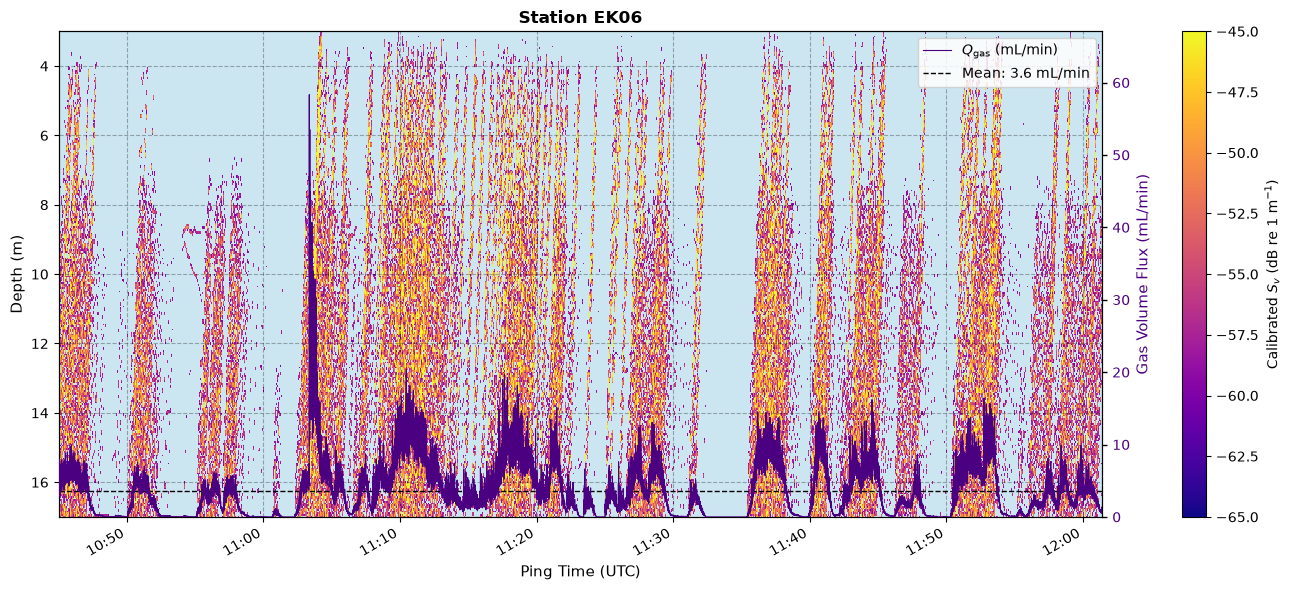

In [11]:
# ==============================================================================
# ECHOGRAM WITH SUPERIMPOSED GAS FLUX OVERLAY (TWIN Y-AXIS)
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. SETUP SINGLE AXIS & TWIN Y-AXIS
fig, ax_echo = plt.subplots(figsize=(14, 6))
ax_flux = ax_echo.twinx()  # Create a second y-axis sharing the same x-axis (time)

# ------------------------------------------------------------------------------
# SET BACKGROUND COLOR
# ------------------------------------------------------------------------------
# Fills background for NaNs / masked regions (e.g. 'black', '#000033', 'slategrey')
ax_echo.set_facecolor("#CBE6F0")  
ax_flux.set_facecolor('none')   # Keep twin axis transparent so echogram shows through

# ------------------------------------------------------------------------------
# 2. BACKGROUND: FILTERED EK80 WIDEBAND Sv ECHOGRAM
# ------------------------------------------------------------------------------
sv_plot_data = sv_db_filtered.values
if sv_plot_data.shape[0] == len(ping_times):
    sv_plot_data = sv_plot_data.T

pcm = ax_echo.pcolormesh(
    ping_times, 
    echo_range, 
    sv_plot_data, 
    cmap='plasma', 
    vmin=-65, 
    vmax=-45, 
    shading='nearest'
)

ax_echo.set_title(
    "Station EK06", 
    fontsize=12, 
    fontweight='bold'
)
ax_echo.set_ylabel("Depth (m)", fontsize=11, color='black')
ax_echo.set_ylim(Z_MIN, Z_MAX)
ax_echo.invert_yaxis()  # Depth increases downwards
ax_echo.grid(True, linestyle="--", alpha=0.3, color='black')

# ------------------------------------------------------------------------------
# 3. FOREGROUND: SUPERIMPOSED GAS VOLUME FLOW RATE (Q_gas)
# ------------------------------------------------------------------------------
mean_q_ml_min = np.nanmean(q_gas_mL_per_min)

# Primary high-visibility flux line
line_flux = ax_flux.plot(
    ping_times, 
    q_gas_mL_per_min, 
    color='indigo', 
    linewidth=0.8, 
    label=r'$Q_{\mathrm{gas}}$ (mL/min)',
    zorder=10
)

# Mean flow rate reference line
line_mean = ax_flux.axhline(
    y=mean_q_ml_min, 
    color='black', 
    linestyle='--', 
    linewidth=1.0, 
    label=f'Mean: {mean_q_ml_min:.1f} mL/min',
    zorder=9
)

ax_flux.set_ylabel("Gas Volume Flux (mL/min)", fontsize=11, color='indigo', fontweight='normal')
ax_flux.tick_params(axis='y', labelcolor='indigo', labelsize=10, width=1.0)
ax_flux.set_ylim(bottom=0, top=np.nanmax(q_gas_mL_per_min) * 1.15)  # Headroom for legend

# ------------------------------------------------------------------------------
# 4. COLORBAR & LEGEND (FIXED POSITIONING)
# ------------------------------------------------------------------------------
# Attach colorbar to ax_flux so it pushes outside the secondary y-axis labels
cbar = fig.colorbar(pcm, ax=ax_flux, pad=0.06, aspect=20)
cbar.set_label(r"Calibrated $S_v$ (dB re $1\ \mathrm{m}^{-1}$)", fontsize=10)

# Combined Legend for the overlay lines
lines = line_flux + [line_mean]
labels = [l.get_label() for l in lines]
ax_flux.legend(lines, labels, loc='upper right', framealpha=0.85, facecolor='white', labelcolor='black')

# ------------------------------------------------------------------------------
# 5. TIME AXIS FORMATTING
# ------------------------------------------------------------------------------
ax_echo.set_xlabel("Ping Time (UTC)", fontsize=11)
ax_echo.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

### 7. Export results

In [20]:
import os
import numpy as np
import pandas as pd
from pathlib import Path
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# ==============================================================================
# 1. HELPER & DATA EXTRACTION FUNCTIONS
# ==============================================================================
def get_var(var_name, fallback="N/A"):
    """Safely retrieves global variables with fallback values."""
    val = globals().get(var_name, fallback)
    if val is None or val == "":
        return fallback
    return str(val) if isinstance(val, Path) else val

# Gather paths dynamically
raw_file = get_var('raw_file_path', 'N/A')
cal_file = get_var('cal_xml_path', 'N/A')
ctd_file = get_var('ctd_path', 'N/A')

# Configure output Excel path
if raw_file != 'N/A' and os.path.isabs(str(raw_file)):
    export_dir = os.path.dirname(str(raw_file))
else:
    export_dir = os.getcwd()

output_excel_path = os.path.join(export_dir, "EK80_Gas_Flux_Full_Summary.xlsx")

# ==============================================================================
# 2. COMPUTATIONS & DATASET PREPARATION
# ==============================================================================
# Environmental CTD
env_temp = globals().get('mean_temp', -1.898)
env_sal = globals().get('mean_sal', 34.700)
env_depth = globals().get('mean_depth', 18.0)

# Physical & Processing Parameters
beamwidth = globals().get('BEAMWIDTH_DEG', 18.0)
bubble_r = globals().get('MEAN_BUBBLE_RADIUS_MM', 5.46)
rise_v = globals().get('RISE_VELOCITY_MS', 0.26)
z_min = globals().get('Z_MIN', 1.9)
z_max = globals().get('Z_MAX', 13.1)
sv_cutoff = globals().get('SV_CUTOFF_DB', -58.0)
vmin = globals().get('VMIN', -70)
vmax = globals().get('VMAX', -25)

# Calculate Flux & Time Series Metrics dynamically if available in memory
if 'q_gas_mL_per_min' in globals() and 'ping_times' in globals():
    p_times = pd.to_datetime(globals()['ping_times'])
    q_gas = np.array(globals()['q_gas_mL_per_min'])
    q_m3s = np.array(globals()['q_gas_m3_per_s'])
    
    # Calculate time differentials
    ping_sec = (p_times - p_times[0]).total_seconds().values
    dt_sec = np.gradient(ping_sec)
    
    total_duration_min = (ping_sec[-1] - ping_sec[0]) / 60.0
    total_volume_L = np.sum(q_m3s * dt_sec) * 1000.0
    
    # Active vs Quiescent mask (> 0.1 mL/min)
    act_threshold = globals().get('ACTIVE_THRESHOLD_ML_MIN', 0.1)
    act_mask = q_gas > act_threshold
    act_time_min = np.sum(dt_sec[act_mask]) / 60.0
    duty_cycle_pct = (act_time_min / total_duration_min) * 100.0
    quiesc_time_min = total_duration_min - act_time_min
    quiesc_pct = 100.0 - duty_cycle_pct
    
    # Statistics
    q_active = q_gas[act_mask] if np.any(act_mask) else q_gas
    
    mean_all = np.nanmean(q_gas)
    median_all = np.nanmedian(q_gas)
    peak_all = np.nanmax(q_gas)
    min_active = np.nanmin(q_gas[q_gas > 0]) if np.any(q_gas > 0) else 0.0
    std_all = np.nanstd(q_gas)
    q25 = np.nanpercentile(q_gas, 25)
    q75 = np.nanpercentile(q_gas, 75)
    iqr = q75 - q25
    
    mean_act = np.mean(q_active)
    med_act = np.median(q_active)
    std_act = np.std(q_active)
    burst_factor = mean_act / mean_all if mean_all > 0 else 1.0
    
    # Primary Periodicity Peak
    dom_period = globals().get('dominant_period', 'N/A')
    
    # Create Ping-by-Ping Time Series DataFrame
    df_timeseries = pd.DataFrame({
        'Ping Time (UTC)': p_times.strftime('%Y-%m-%d %H:%M:%S'),
        'Integrated Sigma_v (m2)': globals().get('sigma_v_total_per_ping', np.zeros_like(q_gas)),
        'Gas Volume Flux (L/min)': globals().get('q_gas_L_per_min', q_gas / 1000.0),
        'Gas Volume Flux (mL/min)': q_gas,
        'Active Seep Flag': act_mask
    })
else:
    # Default fallbacks
    total_duration_min, total_volume_L = 71.14, 0.707
    act_time_min, duty_cycle_pct = 71.16, 100.0
    quiesc_time_min, quiesc_pct = 0.0, 0.0
    mean_all, median_all, peak_all, min_active = 9.93, 9.83, 17.09, 4.11
    std_all, q25, q75, iqr = 1.50, 8.88, 10.89, 2.01
    mean_act, med_act, std_act, burst_factor = 9.93, 9.83, 1.50, 1.00
    dom_period = "N/A"
    df_timeseries = pd.DataFrame()

# ==============================================================================
# 3. BUILD EXECUTIVE SUMMARY DATA SHEETS
# ==============================================================================
summary_rows = [
    ["Parameter / Metric", "Value", "Unit / Description"],
    
    # Section 1
    ["--- FILEPATHS & ENVIRONMENT ---", "", ""],
    ["RAW Data Path", raw_file, "Path"],
    ["Calibration XML Path", cal_file, "Path"],
    ["CTD Profile CSV Path", ctd_file, "Path"],
    ["Mean Temperature", round(env_temp, 3), "°C"],
    ["Mean Salinity", round(env_sal, 3), "PSU"],
    ["Site Evaluation Depth", env_depth, "m"],
    [],
    
    # Section 2
    ["--- ACOUSTIC & PHYSICAL SETTINGS ---", "", ""],
    ["Transducer Beamwidth", beamwidth, "degrees (°)"],
    ["Assumed Bubble Radius (r)", bubble_r, "mm"],
    ["Assumed Rise Velocity (v)", rise_v, "m/s"],
    ["Evaluated Min Depth (Z_MIN)", z_min, "m"],
    ["Evaluated Max Depth (Z_MAX)", z_max, "m"],
    ["Plume Layer Thickness", round(z_max - z_min, 2), "m"],
    ["Sv Cutoff Threshold", sv_cutoff, "dB"],
    ["Colorbar Display Min (VMIN)", vmin, "dB"],
    ["Colorbar Display Max (VMAX)", vmax, "dB"],
    [],
    
    # Section 3
    ["--- GAS FLUX STATISTICAL SUMMARY ---", "", ""],
    ["Total Observation Duration", round(total_duration_min, 2), "minutes"],
    ["Total Integrated Gas Volume Released", round(total_volume_L, 3), "Liters"],
    ["Total Integrated Gas Volume Released", round(total_volume_L * 1000.0, 1), "mL"],
    ["Mean Flow Rate (All-Time)", round(mean_all, 2), "mL/min"],
    ["Median Flow Rate (All-Time)", round(median_all, 2), "mL/min"],
    ["Peak Flow Rate (Maximum)", round(peak_all, 2), "mL/min"],
    ["Min Active Flow Rate", round(min_active, 2), "mL/min"],
    ["Standard Deviation", round(std_all, 2), "mL/min"],
    ["25th Percentile (Q1)", round(q25, 2), "mL/min"],
    ["75th Percentile (Q3)", round(q75, 2), "mL/min"],
    ["Interquartile Range (IQR)", round(iqr, 2), "mL/min"],
    [],
    
    # Section 4
    ["--- ACTIVE vs QUIESCENT ANALYSIS ---", "", ""],
    ["Active Seepage Time", round(act_time_min, 2), f"minutes ({duty_cycle_pct:.1f}% duty cycle)"],
    ["Quiescent / Inactive Time", round(quiesc_time_min, 2), f"minutes ({quiesc_pct:.1f}%)"],
    ["Active Period Mean Flux", round(mean_act, 2), "mL/min"],
    ["Active Period Median Flux", round(med_act, 2), "mL/min"],
    ["Active Period Std Deviation", round(std_act, 2), "mL/min"],
    ["Burst / Active Factor", round(burst_factor, 2), "x higher active vs overall mean"],
    [],
    
    # Section 5
    ["--- PERIODICITY ANALYSIS ---", "", ""],
    ["Dominant Cycle Period (Welch PSD)", round(dom_period, 2) if isinstance(dom_period, (int, float)) else dom_period, "minutes"]
]

df_summary = pd.DataFrame(summary_rows)

# ==============================================================================
# 4. WRITE & FORMAT EXCEL WORKBOOK USING OPENPYXL
# ==============================================================================
with pd.ExcelWriter(output_excel_path, engine='openpyxl') as writer:
    df_summary.to_excel(writer, index=False, header=False, sheet_name="Processing_Summary")
    if not df_timeseries.empty:
        df_timeseries.to_excel(writer, index=False, sheet_name="Ping_by_Ping_Flux")

# --- CUSTOM OPENPYXL STYLING ---
wb = openpyxl.load_workbook(output_excel_path)

# Styles
header_fill = PatternFill(start_color="1F4E78", end_color="1F4E78", fill_type="solid") # Dark Navy
section_fill = PatternFill(start_color="D9E1F2", end_color="D9E1F2", fill_type="solid") # Light Blue
font_header = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
font_section = Font(name="Calibri", size=11, bold=True, color="1F4E78")
font_bold = Font(name="Calibri", size=11, bold=True)
font_regular = Font(name="Calibri", size=11)

thin_border = Border(
    left=Side(style='thin', color='D9D9D9'),
    right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'),
    bottom=Side(style='thin', color='D9D9D9')
)

# Style Sheet 1: Processing_Summary
ws_summary = wb["Processing_Summary"]

# Format headers and sections
for row in ws_summary.iter_rows(min_row=1, max_row=ws_summary.max_row, min_col=1, max_col=3):
    cell_a, cell_b, cell_c = row[0], row[1], row[2]
    
    # Main Header
    if cell_a.row == 1:
        for c in (cell_a, cell_b, cell_c):
            c.fill = header_fill
            c.font = font_header
            c.alignment = Alignment(horizontal="center", vertical="center")
    # Section Header
    elif str(cell_a.value).startswith("---"):
        ws_summary.merge_cells(start_row=cell_a.row, start_column=1, end_row=cell_a.row, end_column=3)
        cell_a.fill = section_fill
        cell_a.font = font_section
        cell_a.alignment = Alignment(horizontal="left", vertical="center")
    # Data Rows
    elif cell_a.value:
        cell_a.font = font_bold
        cell_b.font = font_regular
        cell_c.font = font_regular
        
        cell_a.border = thin_border
        cell_b.border = thin_border
        cell_c.border = thin_border
        
        cell_b.alignment = Alignment(horizontal="right" if isinstance(cell_b.value, (int, float)) else "left")

# Style Sheet 2: Ping_by_Ping_Flux (if present)
if "Ping_by_Ping_Flux" in wb.sheetnames:
    ws_ts = wb["Ping_by_Ping_Flux"]
    for col in range(1, ws_ts.max_column + 1):
        cell = ws_ts.cell(row=1, column=col)
        cell.fill = header_fill
        cell.font = font_header
        cell.alignment = Alignment(horizontal="center")
    
    ws_ts.freeze_panes = 'A2'

# Auto-fit Column Widths across all sheets
for sheet in wb.worksheets:
    for col in sheet.columns:
        max_len = 0
        col_letter = get_column_letter(col[0].column)
        for cell in col:
            val_str = str(cell.value or '')
            if not val_str.startswith("---"):  # Skip long section titles for width calc
                max_len = max(max_len, len(val_str))
        sheet.column_dimensions[col_letter].width = max(max_len + 4, 12)

wb.save(output_excel_path)
print(f"Successfully generated structured multi-tab Excel report at:\n{output_excel_path}")

Successfully generated structured multi-tab Excel report at:
C:\Users\nilr\OneDrive - Universitetssenteret på Svalbard AS\PhD\2026\AFG_CryoSeep\Bubble size distribution\data\EK06\EK80_Gas_Flux_Full_Summary.xlsx


### 8. Periodicity analysis

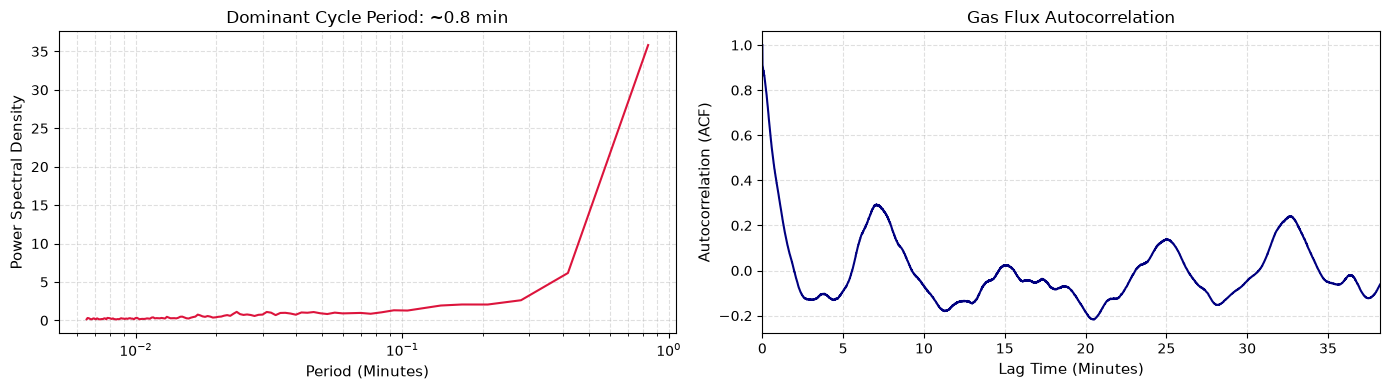

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# Assuming uniform time step dt (in seconds)
dt = np.mean(np.diff(ping_times_sec)) 
fs = 1.0 / dt  # Sampling frequency (Hz)

# 1. POWER SPECTRAL DENSITY (WELCH METHOD)
frequencies, psd = welch(q_gas_mL_per_min - np.nanmean(q_gas_mL_per_min), fs=fs, nperseg=256)

# Convert frequency (Hz) to period (Minutes)
periods_min = (1.0 / frequencies[1:]) / 60.0  # Skip 0 Hz (DC offset)
psd_plot = psd[1:]

# Primary Peak Period
dominant_period = periods_min[np.argmax(psd_plot)]

# 2. AUTOCORRELATION FUNCTION (ACF)
q_zero_mean = q_gas_mL_per_min - np.nanmean(q_gas_mL_per_min)
acf = np.correlate(q_zero_mean, q_zero_mean, mode='full')
acf = acf[len(acf)//2:] / np.max(acf)  # Normalize
lags_min = (np.arange(len(acf)) * dt) / 60.0

# PLOTTING PERIODICITY ANALYSIS
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Spectral Density Plot
ax1.plot(periods_min, psd_plot, color='crimson')
ax1.set_xscale('log')
ax1.set_xlabel('Period (Minutes)', fontsize=11)
ax1.set_ylabel('Power Spectral Density', fontsize=11)
ax1.set_title(f'Dominant Cycle Period: ~{dominant_period:.1f} min', fontsize=12)
ax1.grid(True, which="both", ls="--", alpha=0.4)

# Autocorrelation Plot
ax2.plot(lags_min, acf, color='navy')
ax2.set_xlim(0, total_duration_min / 2)  # Show up to half dataset length
ax2.set_xlabel('Lag Time (Minutes)', fontsize=11)
ax2.set_ylabel('Autocorrelation (ACF)', fontsize=11)
ax2.set_title('Gas Flux Autocorrelation', fontsize=12)
ax2.grid(True, ls="--", alpha=0.4)

plt.tight_layout()
plt.show()